# EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK.


## Download the Dataset

In [1]:

import kagglehub
from kagglehub import KaggleDatasetAdapter
from IPython.display import clear_output

# Filepath to the dataset
file_path = "amz_uk_price_prediction_dataset.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "asaniczka/uk-optimal-product-price-prediction",
  file_path,
)

clear_output()
print("Dataset loaded successfully!")


Dataset loaded successfully!


In [2]:
import pandas as pd

## Initial exploration

- Analyzing a sample of the data and shape
- Verifying the column names
- Extracting the description of each column
- Verifying the data types of each column

In [3]:
# Analyzing a sample of the data and shape
display(df.head())
print("Shape: ", df.shape)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


Shape:  (2443651, 9)


In [4]:
# Verifying the column names
columns = df.columns

print("Columns: ", columns)

Columns:  Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='str')


### Dataset structure

| Column Name | Description |
| :--- | :--- |
| **uid** | Unique identifier for each row. |
| **asin** | Product ID from Amazon. |
| **title** | Title of the product. |
| **stars** | Product rating. If 0, no ratings were found. |
| **reviews** | Number of customer reviews. If 0, no ratings were found. |
| **price** | Price of the product. (Currency: GBP) |
| **isBestSeller** | Product category indicator/Best seller status. |
| **boughtInLastMonth** | Whether the product was bought in the last month. |
| **category** | Indicates products category. |

In [5]:
# Verifying the data types of each column
print("Dataset Types: ")
display(df.info())


Dataset Types: 
<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 151.5 MB


None

In [6]:
if len(df.uid) == df.shape[0]:
    print("uuid can be used as the index of the table")

uuid can be used as the index of the table


In [7]:
# Check for missing data
display(df.eq(" ").sum())
display(df.eq("").sum())

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [8]:
display(df.isna().sum())

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
# Get categorical data
categorical_data = df.select_dtypes(exclude="number")

In [11]:
print("Unique values:")
display(categorical_data.nunique())

Unique values:


asin            2222742
title           2077591
isBestSeller          2
category            296
dtype: int64

In [12]:
print("Data types:")
display(categorical_data.info())

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 4 columns):
 #   Column        Dtype
---  ------        -----
 0   asin          str  
 1   title         str  
 2   isBestSeller  bool 
 3   category      str  
dtypes: bool(1), str(3)
memory usage: 58.3 MB


None

### Part 1: Understanding Product Categories
**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?
2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [13]:
frequency_table = categorical_data.category.value_counts()
proportions_table = categorical_data.category.value_counts(normalize=True)

In [14]:
cat_analysis = pd.concat([frequency_table, proportions_table], axis=1)
cat_analysis["percentage"] = round(cat_analysis.proportion * 100, 3)
display(cat_analysis)

,count,proportion,percentage
category,,,
Sports & Outdoors,836265,0.342219,34.222
Beauty,19312,0.007903,0.790
"Handmade Clothing, Shoes & Accessories",19229,0.007869,0.787
Bath & Body,19092,0.007813,0.781
Birthday Gifts,18978,0.007766,0.777
...,...,...,...
Motorbike Chassis,107,0.000044,0.004
Alexa Built-In Devices,107,0.000044,0.004
Plugs,107,0.000044,0.004


In [15]:
print("Top 5 categories:")
top_5 = cat_analysis[:5]
top_5 = top_5.reset_index()
display(top_5)

Top 5 categories:


,category,count,proportion,percentage
0,Sports & Outdoors,836265,0.342219,34.222
1,Beauty,19312,0.007903,0.790
2,"Handmade Clothing, Shoes & Accessories",19229,0.007869,0.787
3,Bath & Body,19092,0.007813,0.781
4,Birthday Gifts,18978,0.007766,0.777


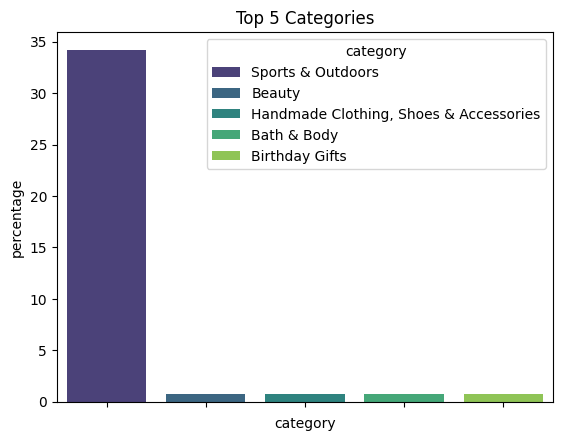

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt 


ax = sns.barplot(x="category", y = "percentage", data=top_5, palette='viridis', hue="category", legend=True)
ax.set_xticklabels([])
ax.set_title("Top 5 Categories")
plt.show()

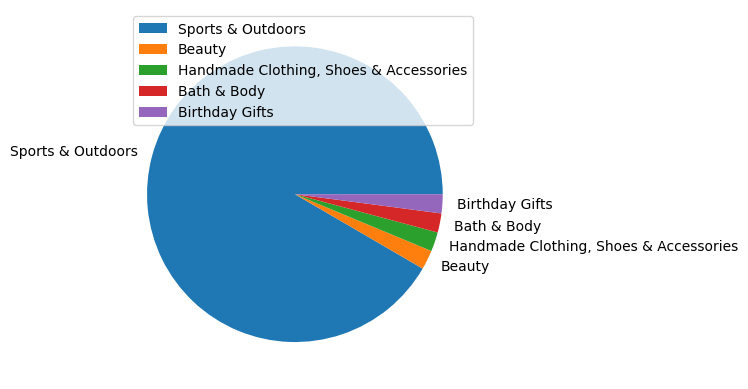

In [17]:
ax = cat_analysis[:5].plot(kind="pie", y="proportion", legend = True )


In [18]:
from IPython.display import Markdown
top_categories = ", ".join(top_5.category.to_list())

report = f"""
### Analysis of Categories

The 5 most listed categories were {top_categories}. A important insight we can extract from the analysis is that
the most listed category is far ahead from all of the other categories with {top_5.percentage.loc[0]}% of the mentions. 
The second most listed has only {top_5.percentage.loc[1]}%.
"""
display(Markdown(report))


### Analysis of Categories

The 5 most listed categories were Sports & Outdoors, Beauty, Handmade Clothing, Shoes & Accessories, Bath & Body, Birthday Gifts. A important insight we can extract from the analysis is that
the most listed category is far ahead from all of the other categories with 34.222% of the mentions. 
The second most listed has only 0.79%.


### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 


In [19]:
# Get numeric data
numeric_data = df.select_dtypes(include="number").drop("uid", axis = 1)

In [20]:
# mode(s)
mode = numeric_data.price.mode()[0]
print("Mode: ", mode)

Mode:  9.99


In [21]:
# mean and median
stats = numeric_data.price.agg(["mean", "median"])
stats

mean      89.243809
median    19.090000
Name: price, dtype: float64

In [22]:
from IPython.display import Markdown


report = f"""
### Conclusion: Measure of centrality

The high value of the mean {round(stats["mean"], 2)}, compared to the median {round(stats["median"], 2)} indicates a positive skewness in prices.
The most common price, the mode, was {mode} which is considerably smaller than the mean and the median.

"""
display(Markdown(report))


### Conclusion: Measure of centrality

The high value of the mean 89.24, compared to the median 19.09 indicates a positive skewness in prices.
The most common price, the mode, was 9.99 which is considerably smaller than the mean and the median.



In [23]:
std = numeric_data.price.std()
variance = numeric_data.price.var()
range = numeric_data.price.max() - numeric_data.price.min()

print("std: ", std)
print("variance: ", variance)
print("range: ", range)

Q1 = numeric_data.price.quantile(0.25)
Q3 = numeric_data.price.quantile(0.75)
IQR = Q3 - Q1
print("IQR: ", IQR)


std:  345.60886175349873
variance:  119445.48532254901
range:  100000.0
IQR:  36.0


In [24]:
from IPython.display import Markdown


report = f"""
### Conclusion: Dispersion

The price distribution for UK Amazon products exhibits a wide dispersion and heavy right-hand tail.

While the interquartile range is {IQR}, i.e. 50% of prices are concentrated in a narrow interval, the absolute range of prices is of {range}, which indicates a heavy influence of outliers.

The standard deviation of {round(std, 2)} and variance {round(variance,2)}, considering a mean of {round(stats["mean"], 2)},
confirms that prices are scattered far from the mean.

A possible insight is that a few luxury items may be strongly affecting the mean.

"""
display(Markdown(report))


### Conclusion: Dispersion

The price distribution for UK Amazon products exhibits a wide dispersion and heavy right-hand tail.

While the interquartile range is 36.0, i.e. 50% of prices are concentrated in a narrow interval, the absolute range of prices is of 100000.0, which indicates a heavy influence of outliers.

The standard deviation of 345.61 and variance 119445.49, considering a mean of 89.24,
confirms that prices are scattered far from the mean.

A possible insight is that a few luxury items may be strongly affecting the mean.



<Axes: xlabel='price', ylabel='Count'>

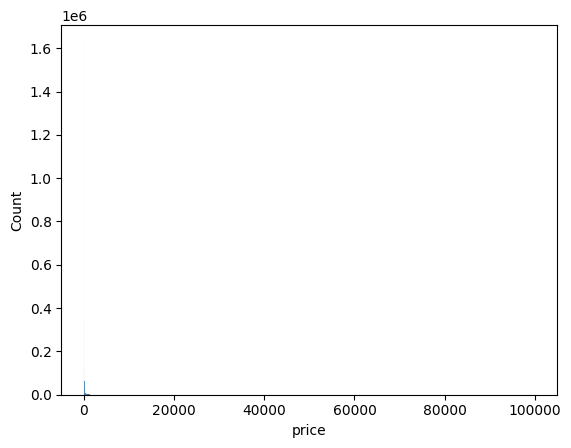

In [25]:
sns.histplot(numeric_data.price, bins="auto")

/var/folders/xm/3ksp3z452z1fgpzrq_nfylnm0000gp/T/ipykernel_7956/296530038.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(numeric_data,


<Axes: ylabel='price'>

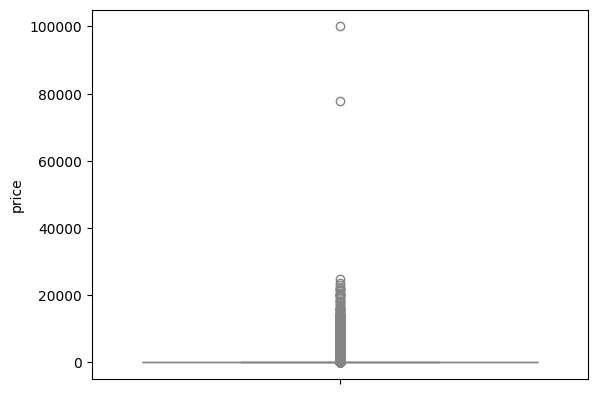

In [26]:
sns.boxplot(numeric_data,
            y = "price",
            palette="coolwarm",
            legend=False)

In [27]:
from IPython.display import Markdown


report = f"""
### Conclusion: Dispersion

The plot for both the histogram and the boxplot are completely unreadable, due to the large
quantity of outliers. It is impossible to see the box, the interquartile range and the median values.
Since most values lie between {Q1} and {Q3},the interquartile range, the next step would be remove
the outliers to properly analyze the data. 

"""
display(Markdown(report))


### Conclusion: Dispersion

The plot for both the histogram and the boxplot are completely unreadable, due to the large
quantity of outliers. It is impossible to see the box, the interquartile range and the median values.
Since most values lie between 9.99 and 45.99,the interquartile range, the next step would be remove
the outliers to properly analyze the data. 



### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

---

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings. 



In [28]:
# mode(s)
mode = numeric_data.stars.mode()[0]
print("Mode: ", mode)

# mean and median
stats = numeric_data.stars.agg(["mean", "median"])
display(stats)



Mode:  0.0


mean      2.152836
median    0.000000
Name: stars, dtype: float64

In [29]:
from IPython.display import Markdown


report = f"""
### Conclusion: Centrality

The most common value in the ratings(stars) was {mode}. The median is also {stats["median"]}.
Since the ratings exactly zero represent the products that didn't receive ratings, it would be 
beneficial to remove them considering their strong presence in the dataset.
The mean of the dataset is equal to {round(stats["mean"],2)}, which also seems to be affected
by the large amount of zeros.

Thus, to have a realistic mean, mode, and median, that reflect our dataset and provide meaninful insights,
its necessary to remove the ratings equal to zero and calculate them again.

"""
display(Markdown(report))


### Conclusion: Centrality

The most common value in the ratings(stars) was 0.0. The median is also 0.0.
Since the ratings exactly zero represent the products that didn't receive ratings, it would be 
beneficial to remove them considering their strong presence in the dataset.
The mean of the dataset is equal to 2.15, which also seems to be affected
by the large amount of zeros.

Thus, to have a realistic mean, mode, and median, that reflect our dataset and provide meaninful insights,
its necessary to remove the ratings equal to zero and calculate them again.



In [30]:
std = numeric_data.stars.std()
variance = numeric_data.stars.var()
range = numeric_data.stars.max() - numeric_data.stars.min()

print("std: ", std)
print("variance: ", variance)
print("range: ", range)

Q1 = numeric_data.stars.quantile(0.25)
Q3 = numeric_data.stars.quantile(0.75)
IQR = Q3 - Q1
print("IQR: ", IQR)


std:  2.194865378513421
variance:  4.817434029796864
range:  5.0
IQR:  4.4


In [31]:
from IPython.display import Markdown


report = f"""
### Conclusion: Dispersion

The stars distribution for UK Amazon products are not properly being represented with the current dataset.

While the interquartile range is {IQR}, i.e. 50% of prices are concentrated in a narrow interval, the absolute range of prices is of {range},
which are close in value. Removing the products that do not have ratings (stars == 0), that interquartile range will probably be smaller.

The standard deviation of {round(std, 2)} and variance {round(variance,2)}, considering a mean of {round(stats["mean"], 2)},
confirms that the zeros are scattering the data, due to the large standard deviation when compared to the data range.

Removing the extra zeros, will bring more clarity to the real distribution of the data.

"""
display(Markdown(report))


### Conclusion: Dispersion

The stars distribution for UK Amazon products are not properly being represented with the current dataset.

While the interquartile range is 4.4, i.e. 50% of prices are concentrated in a narrow interval, the absolute range of prices is of 5.0,
which are close in value. Removing the products that do not have ratings (stars == 0), that interquartile range will probably be smaller.

The standard deviation of 2.19 and variance 4.82, considering a mean of 2.15,
confirms that the zeros are scattering the data, due to the large standard deviation when compared to the data range.

Removing the extra zeros, will bring more clarity to the real distribution of the data.



In [32]:
skew = numeric_data.stars.skew()
print(skew)

if skew == 0:
    print("The distribution is perfectly symmetrical, resembling a normal distribution.")
elif skew>0:
    print("The distribution is positively skewed")
else:
    print("The distribution is negatively skewed")



0.08120735761080881
The distribution is positively skewed


In [33]:
kurtosis = numeric_data.stars.kurtosis()
print(kurtosis)

if kurtosis > 0:
    print("The distribution has a sharp peak and heavy tails (lots of outliers)")

elif kurtosis <0:
    print("The distribution is flat with thin tails.")
else:
    print("The distribution is a standard Normal Distribution (the classic bell curve)")


-1.9260061280432994
The distribution is flat with thin tails.


In [34]:
from IPython.display import Markdown

report = f"""
### Conclusion: Shape

The skewness value of {round(skew, 2)} indicates a positive skew. Additionally, the kurtosis is excessive, with a value of {round(kurtosis, 2)}, which means it's highly non-normal. That is probably an
effect caused by the high frequency of zeros.

"""
display(Markdown(report))


### Conclusion: Shape

The skewness value of 0.08 indicates a positive skew. Additionally, the kurtosis is excessive, with a value of -1.93, which means it's highly non-normal. That is probably an
effect caused by the high frequency of zeros.



<Axes: xlabel='stars', ylabel='Count'>

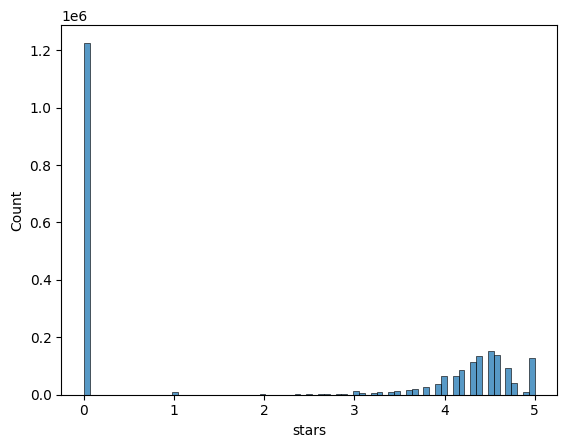

In [35]:
sns.histplot(numeric_data.stars, bins="auto")

In [36]:
from IPython.display import Markdown


report = f"""
### Conclusion: Visualization

As suspected, the excessive amount of zeros prevent the real distribution from surfacing. A visualization is always important to properly investigate
the behaviour of the data. The next step is to remove the outliers and filter the zeros, so that a proper analysis can be conducted.

"""
display(Markdown(report))


### Conclusion: Visualization

As suspected, the excessive amount of zeros prevent the real distribution from surfacing. A visualization is always important to properly investigate
the behaviour of the data. The next step is to remove the outliers and filter the zeros, so that a proper analysis can be conducted.

